<a href="https://colab.research.google.com/github/BackendNeuron/egyptian-arabizi-franco/blob/main/train_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Train the Arabizi → Arabic model on Colab
Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**.

Two stages:
1. **Pre-train** a fresh model on a large synthetic set made from the Egyptian Arabic Wikipedia (downloaded here in Colab, about 200 MB, never stored in the repo).
2. **Fine-tune** it on the hand-written pairs.

Checkpoints are saved to your Google Drive every epoch. If the session is cut off, Run all again: finished stages are skipped and an interrupted one resumes.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/egyptian-arabizi-franco'
!mkdir -p $DRIVE/runs

Mounted at /content/drive


In [2]:
# the code and data, from GitHub
!git clone -q https://github.com/BackendNeuron/egyptian-arabizi-franco.git /content/egyptian-arabizi-franco || (cd /content/egyptian-arabizi-franco && git pull -q)
%cd /content/egyptian-arabizi-franco
!pip -q install -r requirements.txt
# keep runs/ on Drive so checkpoints survive the session
!rm -rf runs && ln -s $DRIVE/runs runs

/content/egyptian-arabizi-franco


In [3]:
# fine-tuning data (hand-written pairs, templates, words and chunks) and the held-out test set
!python tools/build_dataset.py --variants 4
# pre-training data from the Egyptian Arabic Wikipedia (a few minutes the first time)
!python tools/build_pretrain.py --files 2 --max-pairs 300000

seeds 488 · train sentences 1947 · train pairs 8562 · test 76
downloading https://huggingface.co/datasets/wikimedia/wikipedia/resolve/main/20231101.arz/train-00000-of-00003.parquet
downloading https://huggingface.co/datasets/wikimedia/wikipedia/resolve/main/20231101.arz/train-00001-of-00003.parquet
sentences kept 197,170 · chunks 390,000 · pretrain pairs 300,000
   tghna rou7 -> تغنى روح
   al morofwlogya w elousof -> المورفولوجيا و الوصف
   gwrogolnwrthmbrea -> جورجلنورثمبريا
   balemazea -> بالماظة
   ma byn msr oalmeneea -> ما بين مصر والمانيا
   sharekoa motekhassoa fe enoteg -> شركة متخصصة في انتاج
   fe el2ron al tas3 -> في القرن التاسع
   llasharoa lotoghyerat kebeera -> للاشارة لتغييرات كبيرة


In [4]:
import os
# stage 1: pre-train (skipped once runs/pretrain-best.pt exists and the stage finished)
if not os.path.exists('runs/pretrain-done'):
    mode = '--resume' if os.path.exists('runs/pretrain-last.pt') else '--new'
    !python train.py $mode --train-file data/pretrain.tsv --name pretrain- --stage pretrain --epochs 10 --batch 256 --patience 3
    open('runs/pretrain-done', 'w').close()

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(
cuda · 3.2M parameters · 300000 train · 76 test · lr 0.0005
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
epoch   1 · loss 1.653 · test: sentences 7.9% · words 34.0% · char errors 27.7% · 115s
epoch   2 · loss 0.989 · test: sentences 9.2% · words 41.3% · char errors 19.6% · 118s
epoch   3 · loss 0.858 · test: sentences 6.6% · words 45.7% · char errors 16.2% · 120s
epoch   4 · loss 0.797 · test: sentences 9.2% · words 47.1% · char errors 16.5% · 121s
epoch   5 · loss 0.763 · test: sentences 9.2% · words 47.1% · char errors 17.0% · 121s
epoch   6 · loss 0.740 · test: sentence

In [5]:
# stage 2: fine-tune the pre-trained model on the hand-written data, at a lower learning rate
if os.path.exists('runs/last.pt') and os.path.exists('runs/finetune-started'):
    !python train.py --resume --stage finetune --epochs 40
else:
    open('runs/finetune-started', 'w').close()
    !python train.py --continue-from runs/pretrain-best.pt --stage finetune --epochs 40

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(
cuda · 3.2M parameters · 8562 train · 76 test · lr 0.00015
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
epoch   1 · loss 0.817 · test: sentences 27.6% · words 63.5% · char errors 11.5% · 5s
epoch   2 · loss 0.695 · test: sentences 34.2% · words 69.7% · char errors 9.6% · 4s
epoch   3 · loss 0.649 · test: sentences 31.6% · words 71.6% · char errors 9.4% · 4s
epoch   4 · loss 0.619 · test: sentences 28.9% · words 69.2% · char errors 9.9% · 4s
epoch   5 · loss 0.599 · test: sentences 36.8% · words 73.6% · char errors 9.6% · 4s
epoch   6 · loss 0.583 · test: sentences 31.6% · 

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(
charts in /content/egyptian-arabizi-franco/docs/charts


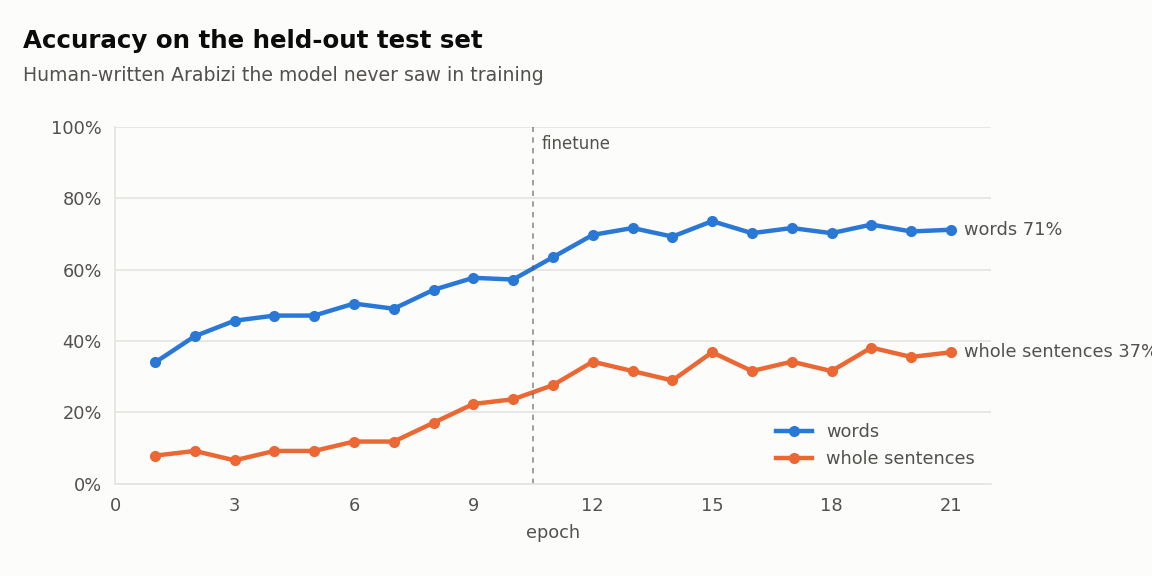

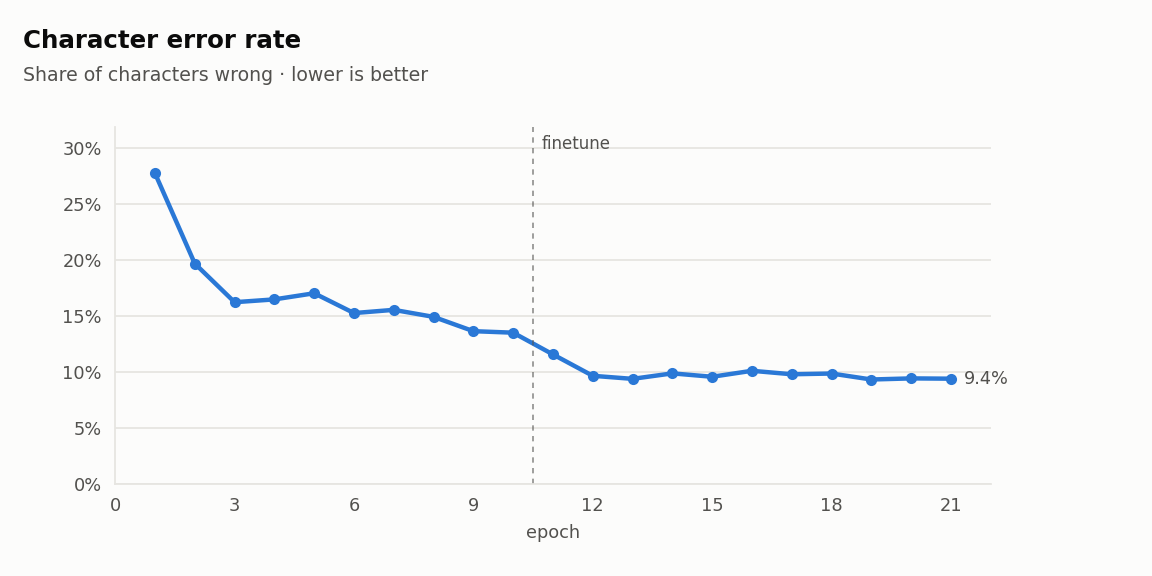

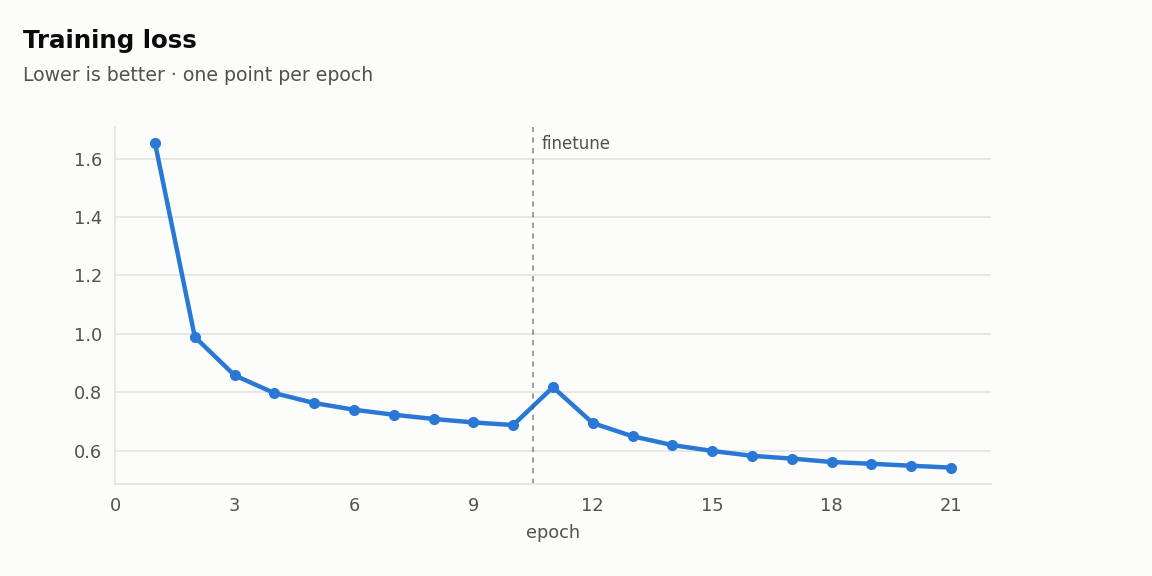

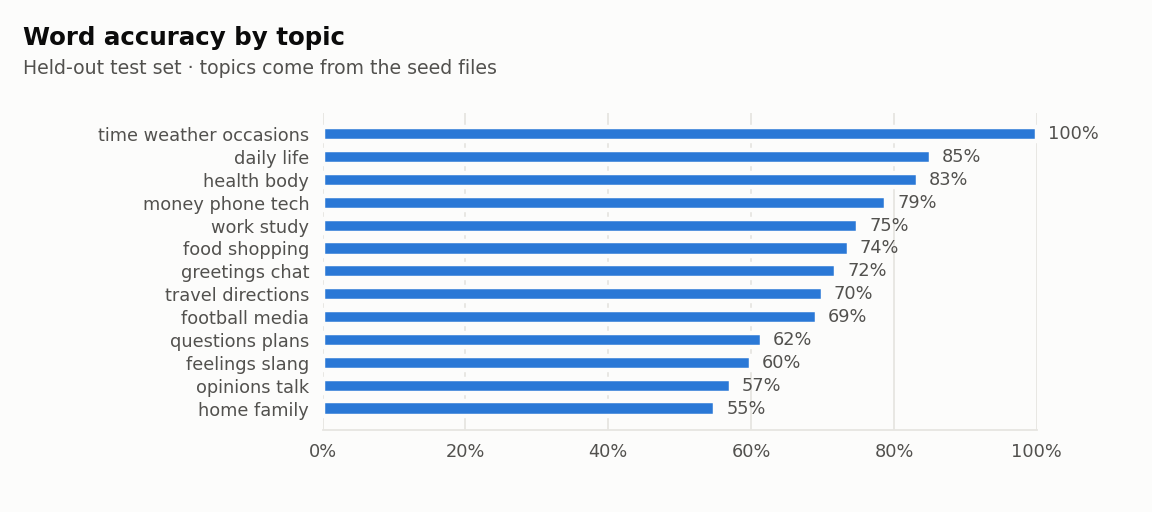

| expected → got | times |
|---|---|
| صباح  →  صابح | 2 |
| ازيك  →  ازايك | 1 |
| ماشي  →  مشي | 1 |
| باشا  →  بشا | 1 |
| فاهم  →  فهم | 1 |
| طيب  →  تايب | 1 |
| ماشفتهاش  →  مشفته | 1 |
| حالا  →  حلان | 1 |
| صداع  →  سودع | 1 |
| حر  →  حار | 1 |
| المفاتيح  →  المفاتح | 1 |
| الجمعة  →  الجومعة | 1 |
| الفطار  →  الفيتر | 1 |
| جاهز  →  جهز | 1 |
| دي  →  راضي | 1 |


In [6]:
!python tools/plots.py --model runs/best.pt
from IPython.display import Image, display, Markdown
for n in ['accuracy', 'cer', 'loss', 'topics']:
    display(Image(f'docs/charts/{n}-light.png'))
display(Markdown(open('docs/charts/mistakes.md', encoding='utf-8').read()))

## Later: continue training on new data
Add sentences to `data/seed/`, rebuild the dataset, then continue from the best model:
```
!python tools/build_dataset.py
!python train.py --continue-from runs/best.pt --stage more-data --epochs 20
```

**Start completely over:** delete `MyDrive/egyptian-arabizi-franco/runs` in Google Drive first.